# Contoh Penerapan Algoritma

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("500_Person_Gender_Height_Weight_Index.csv")
data.head()

,Gender,Height,Weight,Index
0,Male,174,96,4
1,Male,189,87,2
2,Female,185,110,4
3,Female,195,104,3
4,Male,149,61,3


*Identifikasi kategori obesitas*

In [2]:
data['obese'] = (data.Index >= 4).astype('int')
data.drop('Index', axis = 1, inplace = True)

print( 
    " Misclassified when cutting at 100kg:",
    data.loc[(data['Weight']>=100) & (data['obese']==0),:].shape[0],
    "\n", "Misclassified when cutting at 80kg:", 
    data.loc[(data['Weight']>=80) & (data['obese']==0),:].shape[0]
) 

 Misclassified when cutting at 100kg: 18 
 Misclassified when cutting at 80kg: 63


1. Entropy

In [3]:
def entropy(y):
    if isinstance(y, pd.Series):
        a = y.value_counts()/y.shape[0]
        entropy = np.sum(-a*np.log2(a+1e-9))
        return entropy
    else:
        raise ValueError("Input must be a pandas Series")

entropy(data.Gender)

np.float64(0.9997114388674198)

2. Indeks Gini

In [4]:
def gini_impurity(y):
    if isinstance(y, pd.Series):
        p = y.value_counts()/y.shape[0]
        gini = 1 - np.sum(p**2)
        return gini
    else:
        raise ValueError("Input must be a pandas Series")

gini_impurity(data.Gender)

np.float64(0.4998)

3. Information Gain (IG) 

In [5]:
def variance(y):
    if(len(y) == 1):
        return 0
    else:
        return y.var()

def information_gain(y, mask, func=entropy):
    a = sum(mask)
    b = mask.shape[0] - a
    if a == 0 or b == 0:
        ig = 0

    else:
        if y.dtypes != '0':
            ig = variance(y) - (a/(a+b)*variance(y[mask])) - (b/(a+b))*variance(y[~mask])
        else:
            ig = func(y) - (a/(a+b))*func(y[mask]) - (b/(a+b))*func(y[~mask])

    return ig

*Cara Menentukan Pemisahan Terbaik dari Sebuah Variabel*

In [6]:
import itertools
def categorical_options(a):

    a = a.unique()
    opt = []
    for L in range(0, len(a)+1):
        for subset in itertools.combinations(a, L):
            subset = list(subset)
            opt.append(subset)
    return opt[1:-1]

def max_information_gain_split(x, y, func=entropy):
    split_value = []
    ig = []
    numeric_variable = True if x.dtypes != 'O' else False

    if numeric_variable:
        options = x.sort_values().unique()[1:]
    else:
        options = categorical_options(x)

    for val in options:
        mask = x >= val if numeric_variable else x.isin(val)
        val_ig = information_gain(y, mask, func)
        #append results
        ig.append(val_ig)
        split_value.append(val)

    #check if there are more than 1 results if not, return false
    if len(ig) == 0:
        return (None, None, None, False)

    else:
        #get results with highest IG
        best_ig = max(ig)
        best_ig_index = ig.index(best_ig)
        best_split = split_value[best_ig_index]
        return (best_split, best_ig, numeric_variable, True)

weight_ig, weight_split, _, _ = max_information_gain_split(data['Weight'], data['obese'],)
print(
    "The best split for Weight is when the variable is less than ",
    weight_split,
    "\nInformation Gain for that split is:",
    weight_ig
)

The best split for Weight is when the variable is less than  0.10625190497954966 
Information Gain for that split is: 103


*Cara Memilih Pemisahan Terbaik*

In [7]:
data.drop('obese', axis= 1).apply(max_information_gain_split, y = data['obese'])

,Gender,Height,Weight
0,[Male],174,103
1,-0.000281,0.019684,0.106252
2,False,True,True
3,True,True,True


### 1. Cobalah kode pembuatan model Decision Tree hingga evaluasinya sesuai contoh pada modul.

*Cara Melatih Decision Tree dengan Python dari Awal*

1. Menentukan Kedalaman Pohon

In [8]:
def get_best_split(y, data):
    masks = data.drop(y, axis= 1).apply(max_information_gain_split, y = data[y])
    valid = masks.loc[3,:].fillna(False).astype(bool)

    if sum(masks.loc[3,:]) == 0:
        return(None, None, None, None)
    else:
        # Get only masks that can be splitted
        masks = masks.loc[:,masks.loc[3,:]]

        # Get the results for split with highest IG
        split_variable = masks.iloc[1].idxmax()   # baris 1 = IG

        split_value = masks[split_variable][0]    # baris 0 = nilai split
        split_ig = masks[split_variable][1]        # baris 1 = IG
        split_numeric = masks[split_variable][2]

        return(split_variable, split_value, split_ig, split_numeric)

def make_split(variable, value, data, is_numeric):
    if is_numeric:
        data_1 = data[data[variable] < value]
        data_2 = data[(data[variable] < value) == False]
    else:
        data_1 = data[data[variable].isin(value)]
        data_2 = data[(data[variable].isin(value)) == False]
    return(data_1, data_2)

def make_prediction(data, target_factor):
    if target_factor:
        pred = data.value_counts().idxmax()
    else:
        pred = data.mean()

    return(pred)

2. Melatih Decision Tree dengan Python

In [9]:
def train_tree(data,y, target_factor, max_depth = None,min_samples_split = None,min_information_gain = 1e-20, counter=0, max_categories = 20):

    # Check that max_categories is fulfilled
    if counter==0:
        types = data.dtypes
        check_columns = types[types == "object"].index
        for column in check_columns:
            var_length = len(data[column].value_counts())
            if var_length > max_categories:
                raise ValueError('The variable ' + column + ' has '+ str(var_length) + 'unique values, which is more than the accepted ones: ' + str(max_categories))

    #check for depth conditions
    if max_depth ==None:
        depth_cond = True 
    else:
        if counter < max_depth:
            depth_cond = True
        else:
            depth_cond = False

    #check for sample conditions
    if min_samples_split == None:
        sample_cond = True
    else:
        if data.shape[0] >= min_samples_split:
            sample_cond = True
        else:
            sample_cond = False

    # Check for ig condition
    if depth_cond & sample_cond:
        var,val,ig,var_type = get_best_split(y, data)

        # If ig condition is fulfilled, make split
        if ig is not None and ig >= min_information_gain:
            counter += 1
            left,right = make_split(var, val, data,var_type)
            # Instantiate sub-tree

            split_type = "<=" if var_type else "in"
            question = "{} {} {}".format(var,split_type,val)

            # question = "\n" + counter*" " + "|->" + var + " " + split_type + " " + str(val)
            subtree = {question: []}

            # Find answers (recursion)
            yes_answer = train_tree(left,y, target_factor, max_depth,min_samples_split,min_information_gain, counter)
            no_answer = train_tree(right,y, target_factor, max_depth,min_samples_split,min_information_gain, counter)
            if yes_answer == no_answer:
                subtree = yes_answer
            else:
                subtree[question].append(yes_answer)
                subtree[question].append(no_answer)

        else:
            # If ig condition is not fulfilled, make prediction
            pred = make_prediction(data[y], target_factor)
            subtree = pred

    else:
        #drop dataset if doesnt match depth or sample conditions
        pred = make_prediction(data[y], target_factor)
        return pred

    return subtree

max_depth = 5
min_samples_split = 20
min_information_gain = 1e-5


decision = train_tree(
    data,
    y='obese',
    target_factor=True,
    max_depth=max_depth,
    min_samples_split=min_samples_split,
    min_information_gain=min_information_gain
)

decision


C:\Users\USER\AppData\Local\Temp\ipykernel_15824\568909956.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  valid = masks.loc[3,:].fillna(False).astype(bool)
C:\Users\USER\AppData\Local\Temp\ipykernel_15824\568909956.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  valid = masks.loc[3,:].fillna(False).astype(bool)
C:\Users\USER\AppData\Local\Temp\ipykernel_15824\568909956.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. T

{'Weight <= 103': [{'Height <= 175': [{'Weight <= 74': [{'Height <= 148': [np.int64(1),
        np.int64(0)]},
      {'Height <= 162': [np.int64(1),
        {'Weight <= 82': [np.int64(0), np.int64(1)]}]}]},
    np.int64(0)]},
  {'Height <= 189': [{'Weight <= 116': [{'Height <= 168': [np.int64(1),
        {'Height <= 169': [np.int64(0), np.int64(1)]}]},
      np.int64(1)]},
    {'Weight <= 115': [np.int64(0), np.int64(1)]}]}]}

*Prediksi Menggunakan Decision Tree dengan Python*

In [10]:
def classifier_data(observation, arbol):
    question = list(arbol.keys())[0]

    if question.split()[1] == '<=':
        if observation[question.split()[0]] <= float(question.split()[2]):
            answer = arbol[question][0]
        else:
            answer = arbol[question][1]
    else:
        if observation[question.split()[0]] in (question.split()[2]):
            answer = arbol[question][0]
        else:
            answer = arbol[question][1]

    # If the answer is not a dictionary
    if not isinstance(answer, dict):
        return answer
    else:
        residual_tree = answer
        return classifier_data(observation, answer)
#Prediction
obese_prediction = []
num_obs = 50

for i in range(num_obs):
    obs_pred = classifier_data(data.iloc[i,:], decision)
    obese_prediction.append(obs_pred)

print("No. | Prediction | Real value")
for i, (prediction, real_value) in enumerate(
    zip(obese_prediction, data.obese[:num_obs].to_numpy()),
    start=1,
 ):
    print(f"{i:>3} | {prediction:^10} | {real_value:^10}")

No. | Prediction | Real value
  1 |     1      |     1     
  2 |     0      |     0     
  3 |     1      |     1     
  4 |     0      |     0     
  5 |     0      |     0     
  6 |     1      |     0     
  7 |     1      |     1     
  8 |     1      |     1     
  9 |     1      |     0     
 10 |     1      |     1     
 11 |     0      |     0     
 12 |     1      |     1     
 13 |     0      |     0     
 14 |     0      |     0     
 15 |     0      |     0     
 16 |     1      |     1     
 17 |     1      |     1     
 18 |     1      |     1     
 19 |     1      |     1     
 20 |     1      |     1     
 21 |     1      |     1     
 22 |     1      |     1     
 23 |     1      |     1     
 24 |     1      |     1     
 25 |     0      |     0     
 26 |     0      |     0     
 27 |     0      |     0     
 28 |     0      |     0     
 29 |     1      |     1     
 30 |     1      |     1     
 31 |     1      |     1     
 32 |     0      |     0     
 33 |     

*Evaluasi: Confusion Matrix*

In [11]:
# Calculate the confusion matrix
from sklearn import metrics
observation = data.obese[:num_obs].to_numpy()
answer = obese_prediction
confusion_matrix = metrics.confusion_matrix(observation, answer)

# Menghitung Akurasi
Accuracy = metrics.accuracy_score(observation, answer)

# Menghitung Presisi
Precision = metrics.precision_score(observation, answer)

# Menghitung Sensitivitas
Sensitivity_recall = metrics.recall_score(observation, answer)

# Menghitung Spesifisitas
Specificity = metrics.recall_score(observation, answer, pos_label=0)

# Menghitung F-Score
F1_score = metrics.f1_score(observation, answer)

print(
    f"Accuracy: {Accuracy}\n"
    f"Precision: {Precision}\n"
    f"Sensitivity: {Sensitivity_recall}\n"
    f"Specificity: {Specificity}\n"
    f"F1-score: {F1_score}"
)

Accuracy: 0.96
Precision: 0.9375
Sensitivity: 1.0
Specificity: 0.9
F1-score: 0.967741935483871


### 2. Ubahlah fungsi pemisahan menjadi Gini index dari entropi!

In [12]:
from sklearn import metrics


def gini_impurity_new(y):
    probabilities = y.value_counts(normalize=True)
    return 1 - np.sum(probabilities ** 2)


def gini_split_score(y, mask):
    left = y[mask]
    right = y[~mask]

    if left.empty or right.empty:
        return 0

    parent_gini = gini_impurity_new(y)
    children_gini = (
        len(left) / len(y) * gini_impurity_new(left)
        + len(right) / len(y) * gini_impurity_new(right)
    )
    return parent_gini - children_gini


def best_gini_split(feature, target):
    best_value = None
    best_score = -1

    for value in np.sort(feature.unique())[1:]:
        score = gini_split_score(target, feature < value)
        if score > best_score:
            best_value = value
            best_score = score

    return best_value, best_score


best_splits_gini = {
    feature: best_gini_split(data[feature], data['obese'])
    for feature in ['Height', 'Weight']
}
best_feature_gini = max(best_splits_gini, key=lambda feature: best_splits_gini[feature][1])

print('Gini impurity awal:', round(gini_impurity_new(data['obese']), 4))
print('Split terbaik per fitur:', best_splits_gini)
print('Fitur split terbaik:', best_feature_gini)

# Model satu split Gini untuk melihat hasil klasifikasi secara langsung.
best_value_gini, _ = best_splits_gini[best_feature_gini]
prediction_gini = np.where(
    data[best_feature_gini] < best_value_gini,
    data.loc[data[best_feature_gini] < best_value_gini, 'obese'].mode()[0],
    data.loc[data[best_feature_gini] >= best_value_gini, 'obese'].mode()[0],
)

print('\nEvaluasi model Gini:')
print('Confusion matrix:\n', metrics.confusion_matrix(data['obese'], prediction_gini))
print('Accuracy:', round(metrics.accuracy_score(data['obese'], prediction_gini), 4))
print('Precision:', round(metrics.precision_score(data['obese'], prediction_gini), 4))
print('Recall:', round(metrics.recall_score(data['obese'], prediction_gini), 4))
print('F1-score:', round(metrics.f1_score(data['obese'], prediction_gini), 4))

Gini impurity awal: 0.4513
Split terbaik per fitur: {'Height': (np.int64(174), np.float64(0.04014551824817508)), 'Weight': (np.int64(103), np.float64(0.2126150333070142))}
Fitur split terbaik: Weight

Evaluasi model Gini:
Confusion matrix:
 [[160  12]
 [ 69 259]]
Accuracy: 0.838
Precision: 0.9557
Recall: 0.7896
F1-score: 0.8648


### 3. Membagi dataset 'Iris' dengan pembagian sesuai pada modul 

In [13]:
import pandas as pd
import numpy as np 
from ucimlrepo import fetch_ucirepo 

# fetch dataset 
iris = fetch_ucirepo(id=53) 
  
# data (as pandas dataframes) 
X = iris.data.features 
y = iris.data.targets 

df = iris.dataframe 
# Build the dataframe from the fetched features and target.
df = pd.concat([X, y], axis=1)
df = df.rename(columns={"class": "Species"})

from sklearn.model_selection import train_test_split

# Pisahkan fitur dan target dari dataset Iris
X_iris = df.drop('Species', axis=1)
y_iris = df['Species']

# 70% data untuk training dan 30% data untuk testing
X_train_iris, X_test_iris, y_train_iris, y_test_iris = train_test_split(
    X_iris,
    y_iris,
    test_size=0.30,
    random_state=42,
    stratify=y_iris
)
print('Data awal:')
print(df.head())

print('\nJumlah data awal:', len(df))
print('Jumlah data training:', len(X_train_iris))
print('Jumlah data testing:', len(X_test_iris))
print('\nUkuran X_train:', X_train_iris.shape)
print('Ukuran X_test:', X_test_iris.shape)
print('\nDistribusi kelas pada data training:')
print(y_train_iris.value_counts())
print('\nDistribusi kelas pada data testing:')
print(y_test_iris.value_counts())

# metadata 
print(iris.metadata) 
  
# variable information 
print(iris.variables) 

Data awal:
   sepal length  sepal width  petal length  petal width      Species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa

Jumlah data awal: 150
Jumlah data training: 105
Jumlah data testing: 45

Ukuran X_train: (105, 4)
Ukuran X_test: (45, 4)

Distribusi kelas pada data training:
Species
Iris-versicolor    35
Iris-setosa        35
Iris-virginica     35
Name: count, dtype: int64

Distribusi kelas pada data testing:
Species
Iris-virginica     15
Iris-versicolor    15
Iris-setosa        15
Name: count, dtype: int64
{'uci_id': 53, 'name': 'Iris', 'repository_url': 'https://archive.ics.uci.edu/dataset/53/iris', 'data_url': 'https://archive.ics.uci.edu/static/public/53/data.csv', 'abstract': '

**a. Perbandingan Decision Tree: Gini dan Entropy**

In [14]:
from sklearn.tree import DecisionTreeClassifier

model_gini = DecisionTreeClassifier(criterion='gini', random_state=42)
model_entropy = DecisionTreeClassifier(criterion='entropy', random_state=42)

model_gini.fit(X_train_iris, y_train_iris)
model_entropy.fit(X_train_iris, y_train_iris)

print('Jumlah data training:', len(X_train_iris))

Jumlah data training: 105


**b. Memprediksi data testing dengan kedua model**

In [ ]:
prediction_gini_iris = model_gini.predict(X_test_iris)
prediction_entropy_iris = model_entropy.predict(X_test_iris)

print('Prediksi model Gini:')
print(prediction_gini_iris)
print('\nPrediksi model Entropy:')
print(prediction_entropy_iris)

Prediksi model Gini:
['Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-virginica' 'Iris-setosa' 'Iris-setosa'
 'Iris-virginica' 'Iris-virginica' 'Iris-setosa' 'Iris-virginica'
 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa'
 'Iris-versicolor' 'Iris-setosa' 'Iris-versicolor' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-versicolor' 'Iris-setosa' 'Iris-virginica' 'Iris-virginica'
 'Iris-virginica' 'Iris-setosa' 'Iris-virginica' 'Iris-setosa'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-virginica'
 'Iris-versicolor' 'Iris-setosa' 'Iris-virginica' 'Iris-virginica'
 'Iris-versicolor']

Prediksi model Entropy:
['Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica'
 'Iris-versicolor' 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor'
 'Iris-setosa' 'Iris-virginica' 'Iris-setosa' 'Iris-setosa'
 'Iris-

**c. Membuat confusion matrix untuk masing-masing mode**

In [16]:
from sklearn.metrics import confusion_matrix

labels_iris = sorted(y_test_iris.unique())
confusion_gini = confusion_matrix(
    y_test_iris,
    prediction_gini_iris,
    labels=labels_iris,
)
confusion_entropy = confusion_matrix(
    y_test_iris,
    prediction_entropy_iris,
    labels=labels_iris,
)

print('Confusion Matrix - Gini:')
print(pd.DataFrame(confusion_gini, index=labels_iris, columns=labels_iris))
print('\nConfusion Matrix - Entropy:')
print(pd.DataFrame(confusion_entropy, index=labels_iris, columns=labels_iris))

Confusion Matrix - Gini:
                 Iris-setosa  Iris-versicolor  Iris-virginica
Iris-setosa               15                0               0
Iris-versicolor            0               12               3
Iris-virginica             0                0              15

Confusion Matrix - Entropy:
                 Iris-setosa  Iris-versicolor  Iris-virginica
Iris-setosa               15                0               0
Iris-versicolor            0               13               2
Iris-virginica             0                3              12


**d. Menghitung accuracy, precision, sensitivity, dan specificity**

In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
import numpy as np


def calculate_specificity(matrix, class_index):
    true_negative = matrix.sum() - matrix[class_index, :].sum() - matrix[:, class_index].sum() + matrix[class_index, class_index]
    false_positive = matrix[:, class_index].sum() - matrix[class_index, class_index]
    return true_negative / (true_negative + false_positive)


def calculate_metrics(y_true, y_pred, matrix):
    specificities = [
        calculate_specificity(matrix, index)
        for index in range(len(labels_iris))
    ]

    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'Sensitivity (Recall)': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'Specificity (Macro)': np.mean(specificities),
    }


metrics_gini = calculate_metrics(y_test_iris, prediction_gini_iris, confusion_gini)
metrics_entropy = calculate_metrics(y_test_iris, prediction_entropy_iris, confusion_entropy)

print('Metrik Decision Tree Gini:')
print(pd.Series(metrics_gini).round(4))
print('\nMetrik Decision Tree Entropy:')
print(pd.Series(metrics_entropy).round(4))

Metrik Decision Tree Gini:
Accuracy                0.9333
Precision               0.9444
Sensitivity (Recall)    0.9333
Specificity (Macro)     0.9667
dtype: float64

Metrik Decision Tree Entropy:
Accuracy                0.8889
Precision               0.8899
Sensitivity (Recall)    0.8889
Specificity (Macro)     0.9444
dtype: float64


In [18]:
# e. Membandingkan dan menganalisis hasil kedua model
comparison_iris = pd.DataFrame(
    [metrics_gini, metrics_entropy],
    index=['Decision Tree - Gini', 'Decision Tree - Entropy'],
)

print('Perbandingan hasil:')
print(comparison_iris.round(4))

best_model = comparison_iris['Accuracy'].idxmax()


Perbandingan hasil:
                         Accuracy  Precision  Sensitivity (Recall)  \
Decision Tree - Gini       0.9333     0.9444                0.9333   
Decision Tree - Entropy    0.8889     0.8899                0.8889   

                         Specificity (Macro)  
Decision Tree - Gini                  0.9667  
Decision Tree - Entropy               0.9444  


Analisis:
- Model dengan accuracy tertinggi adalah Decision Tree - Gini.
- Gini dan Entropy dapat menghasilkan struktur tree yang berbeda karena formula impurity-nya berbeda.
- Accuracy menunjukkan proporsi prediksi yang benar dari seluruh data testing.
- Precision menunjukkan ketepatan prediksi kelas yang dihasilkan model.
- Sensitivity/Recall menunjukkan kemampuan model mengenali data dari kelas yang sebenarnya.
- Specificity menunjukkan kemampuan model menolak data yang bukan anggota kelas tersebut.

### 4. Percobaan kode pembuatan model Random Forest hingga evaluasinya sesuai Contoh 1-3 pada modul.

**Random Forest**

*Contoh 1: Membangun Kelas Dasar Pemodelan Random Forest*

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.datasets import load_wine
from sklearn.model_selection import StratifiedKFold,cross_validate
from sklearn.metrics import accuracy_score,precision_score,recall_score,mean_absolute_error,mean_squared_error,r2_score,make_scorer
from abc import ABC,abstractmethod
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin
#from decisiontrees import DecisionTreeClassifier, DecisionTreeRegressor

from abc import ABC, abstractmethod
from sklearn.base import clone

class RandomForest(BaseEstimator, ClassifierMixin, ABC):
    #initializer
    def __init__(self, n_trees=100):
        self.n_trees = n_trees
        self.trees = []

    #private function to make bootstrap samples
    def __make_bootstraps(self, data):
        dc = {}
        unip = 0
        b_size = data.shape[0]
        idx = [i for i in range(b_size)]
        for b in range(self.n_trees):
            sidx = np.random.choice(idx, replace=True, size=b_size)
            b_samp = data[sidx, :]
            unip += len(set(sidx))
            oidx = list(set(idx) - set(sidx))
            o_samp = np.array([])
            if oidx:
                o_samp = data[oidx, :]
            dc['boot_' + str(b)] = {'boot': b_samp, 'test': o_samp}
        return dc

    #public function to return model parameters
    def get_params(self, deep=False):
        return {'n_trees': self.n_trees}

    #protected function to obtain the right decision tree
    @abstractmethod
    def _make_tree_model(self):
        pass

    #protected function to train the ensemble
    def _train(self, X_train, y_train):
        training_data = np.concatenate((X_train, y_train.reshape(-1, 1)), axis=1)
        dcBoot = self.__make_bootstraps(training_data)
        tree_m = self._make_tree_model()
        dcOob = {}
        for b in dcBoot:
            model = clone(tree_m)
            model.fit(dcBoot[b]['boot'][:, :-1], dcBoot[b]['boot'][:, -1].reshape(-1, 1))
            self.trees.append(model)
            if dcBoot[b]['test'].size:
                dcOob[b] = dcBoot[b]['test']
            else:
                dcOob[b] = np.array([])
        return dcOob

    #protected function to predict from the ensemble
    def _predict(self, X):
        if not self.trees:
            print('You must train the ensemble before making predictions!')
            return None
        predictions = []
        for m in self.trees:
            yp = m.predict(X)
            predictions.append(yp.reshape(-1, 1))
        ypred = np.mean(np.concatenate(predictions, axis=1), axis=1)
        return ypred

*Contoh 2: Membangun Model Classifier Berbasis Algoritma Random Forest*

In [20]:
#class for random forest classifier
class RandomForestClassifierCustom(RandomForest):
    #initializer
    def __init__(self,n_trees=100,max_depth: int=None,min_samples_split:int=2,criterion: str='gini',class_weights='balanced'):
        super().__init__(n_trees)
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.criterion = criterion
        self.class_weights = class_weights
        #protected function to obtain the right decision tree
    def _make_tree_model(self):
        return(DecisionTreeClassifier(max_depth = self.max_depth,
                                        min_samples_split = self.min_samples_split,
                                        criterion = self.criterion,
                                        class_weight = self.class_weights))
    #public function to return model parameters
    def get_params(self, deep = False):
            return {'n_trees':self.n_trees,
                    'max_depth':self.max_depth,
                    'min_samples_split':self.min_samples_split,
                    'criterion':self.criterion,
                    'class_weights':self.class_weights}
    #train the ensemble
    def fit(self,X_train,y_train,print_metrics=False):
        #call the protected training method
        dcOob = self._train(X_train,y_train)
        #if selected, compute the standard errors and print them
        if print_metrics:
            #initialise metric arrays
            accs = np.array([])
            pres = np.array([])
            recs = np.array([])
            #loop through each bootstrap sample
            for b,m in zip(dcOob,self.trees):
                #compute the predictions on the out-of-bag test set & compute metrics
                if dcOob[b].size:
                    yp = m.predict(dcOob[b][:,:-1])
                    acc = accuracy_score(dcOob[b][:,-1],yp)
                    pre = precision_score(dcOob[b][:,-1],yp,average='weighted')
                    rec = recall_score(dcOob[b][:,-1],yp,average='weighted')
                    #store the error metrics
                    accs = np.concatenate((accs,acc.flatten()))
                    pres = np.concatenate((pres,pre.flatten()))
                    recs = np.concatenate((recs,rec.flatten()))
                    
            #print standard errors
            print("Standard error in accuracy: %.2f" % np.std(accs))
            print("Standard error in precision: %.2f" % np.std(pres))
            print("Standard error in recall: %.2f" % np.std(recs))

    #predict from the ensemble
    def predict(self,X):
        #call the protected prediction method
        ypred = self._predict(X)
        #convert the results into integer values & return
        return(np.round(ypred).astype(int))



*Contoh 3: Menerapkan Model Classifier Random Forest Pada Kasus*

Dimensions of X:  (178, 13)
Dimensions of y:  (178,)
Classes in the label:  [0 1 2]


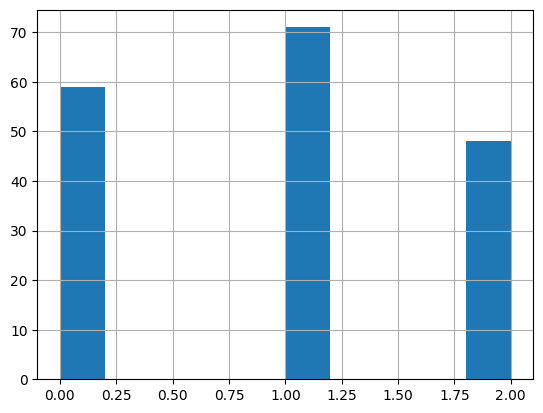

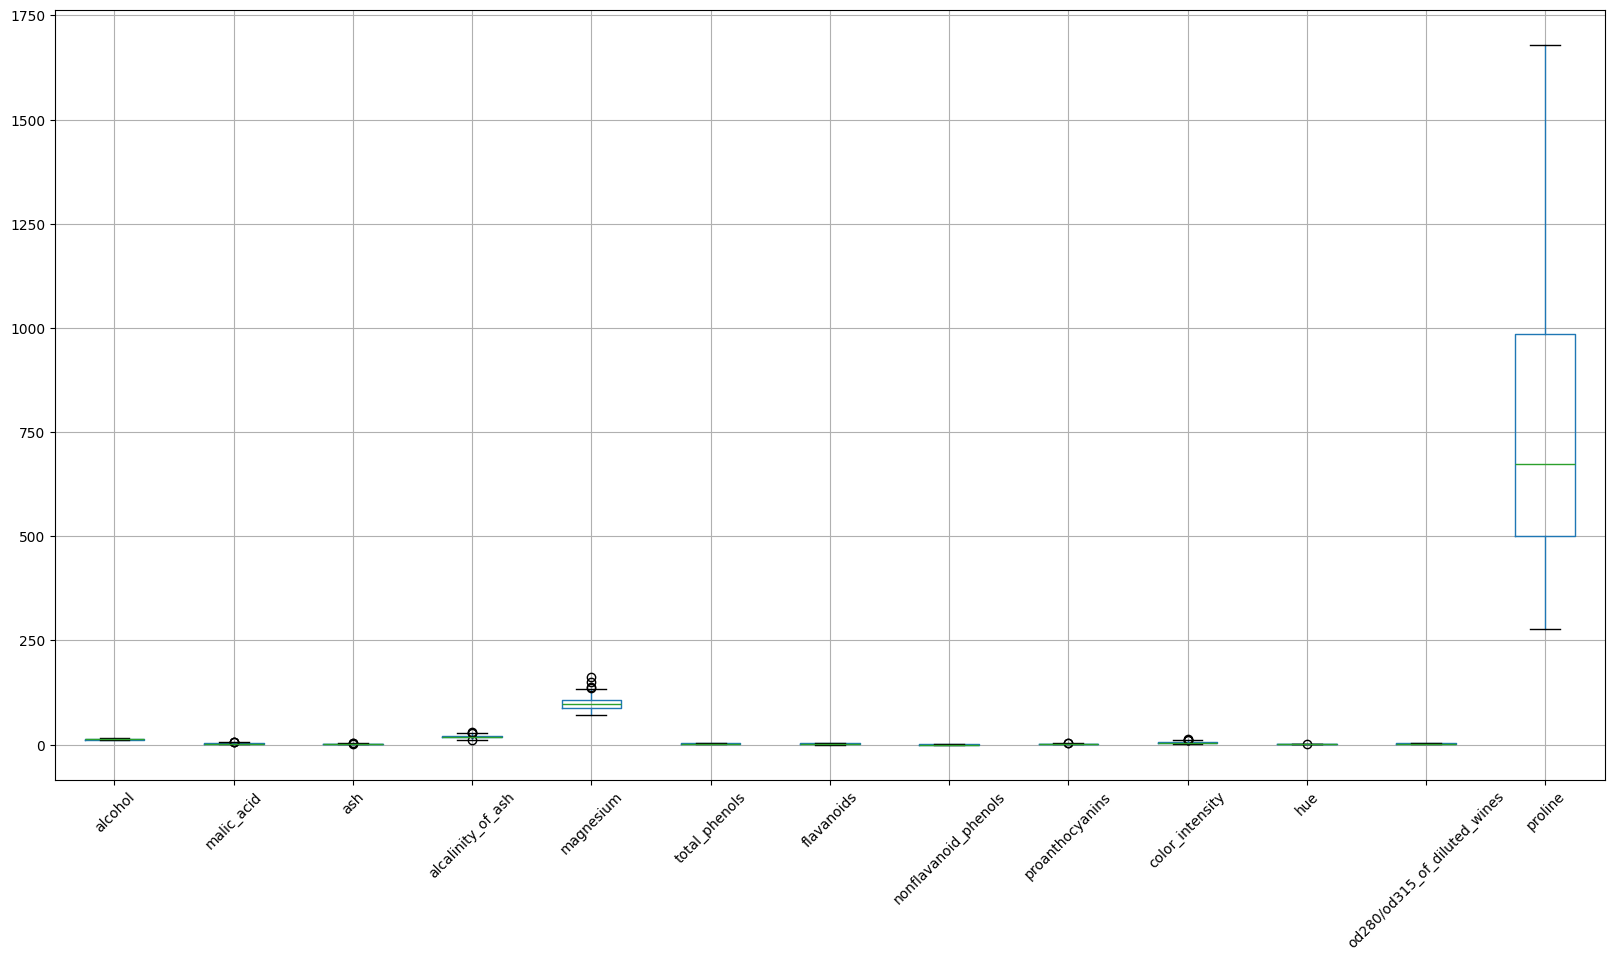

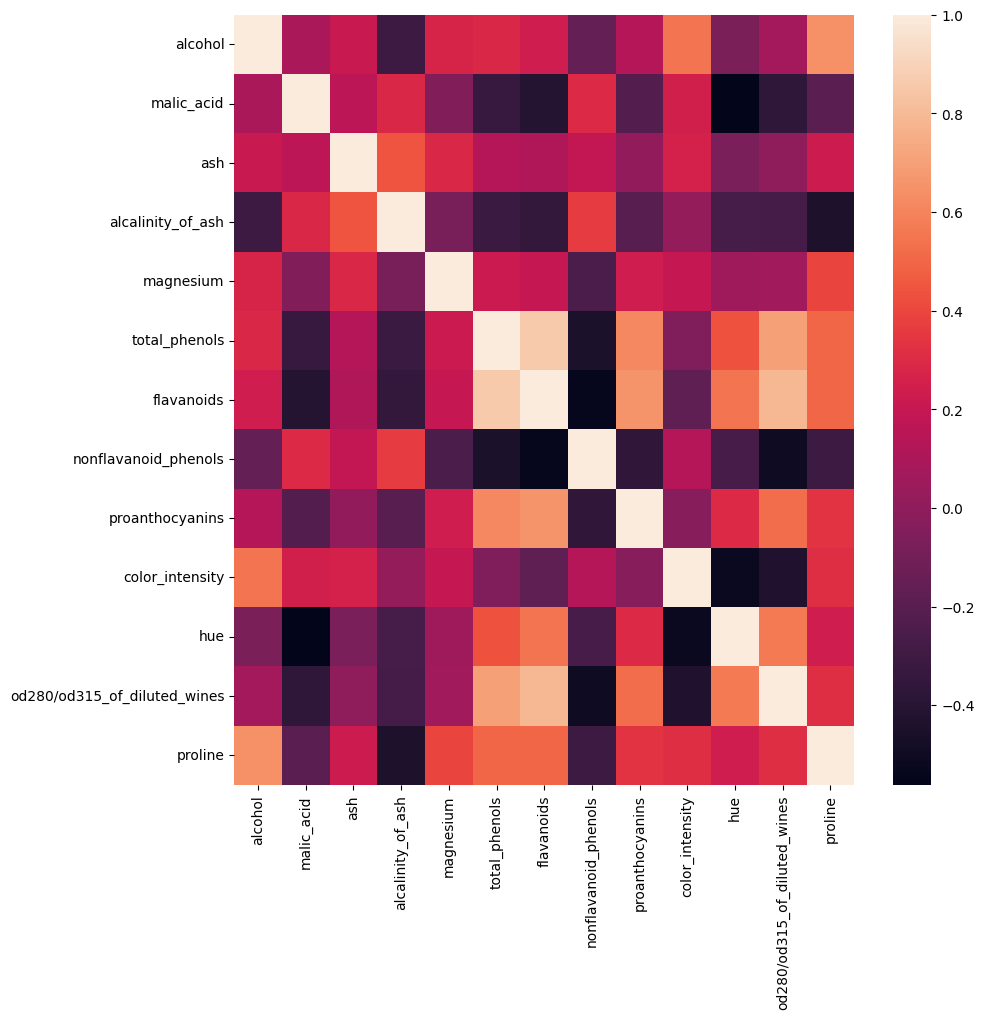

highly correlated input features:  total_phenols  &  ['flavanoids']
highly correlated input features:  flavanoids  &  ['total_phenols']
Mean Accuracy: 0.93
Mean Precision: 0.94
Mean Recall: 0.93


In [21]:
#load the wine dataset 
dfX,sY = load_wine(return_X_y=True, as_frame=True) 
 
#check the dimensions of these data 
print('Dimensions of X: ',dfX.shape) 
print('Dimensions of y: ',sY.shape) 
 
#what unique classes exist in the label variable? 
print('Classes in the label: ',sY.unique()) 
 
#what is the frequency of the classes in the dataset? 
sY.hist() 
plt.show() 
 
#view the first 5 rows of input features 
dfX.head(5) 
 
#make a boxplot to view the distribution in these data 
dfX.boxplot(figsize=(20,10),rot=45) 
plt.show() 
 
## plot the pearson correlation for our input features ## 
fig, ax = plt.subplots(figsize = (10, 10)) 
dfCorr  = dfX.corr() 
sn.heatmap(dfCorr) 
plt.show() 
 
#convert all correlations to positive values 
dfCorr = dfCorr.abs() 
 
#loop through rows 
for index, sRow in dfCorr.iterrows(): 
    #get the valid entries 
    sCorrs = sRow[sRow.index != index] 
    sCorrs = sCorrs[sCorrs > 0.8] 
    #print out results 
    if not sCorrs.empty: 
        print('highly correlated input features: ',index,' & ',sCorrs.index.values) 
 
#create a random forest with balance class weights enabled 
rfcC = RandomForestClassifierCustom(class_weights='balanced') 
 
#train the ensemble & view estimates for prediction error ## 
rfcC.fit(dfX.values,sY.values,print_metrics=False) 

## use k fold cross validation to measure performance ## 
scoring_metrics = {'accuracy': make_scorer(accuracy_score), 
                   'precision': make_scorer(precision_score, average='weighted'), 
                   'recall': make_scorer(recall_score, average='weighted')} 
dcScores = cross_validate(rfcC,dfX.values,sY.values,cv=StratifiedKFold(10),scoring=scoring_metrics) 
print('Mean Accuracy: %.2f' % np.mean(dcScores['test_accuracy'])) 
print('Mean Precision: %.2f' % np.mean(dcScores['test_precision'])) 
print('Mean Recall: %.2f' % np.mean(dcScores['test_recall']))

*Contoh 4: Membandingkan Hasil Evaluasi Algoritma Random Forest dengan Scikit-Learn*

In [22]:
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier 
from sklearn.tree import DecisionTreeClassifier 
 
#create a random forest with balanced class weights 
rfc = RandomForestClassifier(class_weight='balanced') 
 
## use k fold cross validation to measure performance ## 
scoring_metrics = {'accuracy': make_scorer(accuracy_score), 
                   'precision': make_scorer(precision_score, 
                    average='weighted'), 
                   'recall': make_scorer(recall_score, average='weighted')} 
dcScores = cross_validate(rfc,dfX.values,sY.values,cv=StratifiedKFold(10),scoring=scoring_metrics) 
print('Mean Accuracy: %.2f' % np.mean(dcScores['test_accuracy'])) 
print('Mean Precision: %.2f' % np.mean(dcScores['test_precision'])) 
print('Mean Recall: %.2f' % np.mean(dcScores['test_recall'])) 

Mean Accuracy: 0.99
Mean Precision: 0.99
Mean Recall: 0.99


### 5. Membandingkan hasil evaluasi klasifikasi wine dataset

In [23]:
# Membandingkan empat model klasifikasi sesuai tabel pada soal
from sklearn.base import clone
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score, average='weighted', zero_division=0),
    'recall': make_scorer(recall_score, average='weighted', zero_division=0),
}

models = {
    'Random Forest (Manual)': RandomForestClassifierCustom(
        n_trees=100,
        class_weights='balanced',
    ),
    'Random Forest (Scikit-Learn)': RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
    ),
    'Decision Tree (Manual)': DecisionTreeClassifier(
        criterion='gini',
        class_weight='balanced',
        random_state=42,
    ),
    'Decision Tree (Scikit-Learn)': DecisionTreeClassifier(
        criterion='entropy',
        class_weight='balanced',
        random_state=42,
    ),
}

hasil_evaluasi = []
for nama_model, model in models.items():
    skor = cross_validate(
        clone(model),
        dfX.values,
        sY.values,
        cv=cv,
        scoring=scoring,
    )
    hasil_evaluasi.append({
        'Algoritma Klasifikasi': nama_model,
        'Rerata Akurasi (%)': np.mean(skor['test_accuracy']) * 100,
        'Rerata Presisi (%)': np.mean(skor['test_precision']) * 100,
        'Rerata Recall (%)': np.mean(skor['test_recall']) * 100,
    })

tabel_perbandingan = pd.DataFrame(hasil_evaluasi).set_index('Algoritma Klasifikasi')
print('Perbandingan hasil evaluasi klasifikasi:')
display(tabel_perbandingan.round(2))


Perbandingan hasil evaluasi klasifikasi:


,Rerata Akurasi (%),Rerata Presisi (%),Rerata Recall (%)
Algoritma Klasifikasi,,,
Random Forest (Manual),95.56,95.97,95.56
Random Forest (Scikit-Learn),98.33,98.60,98.33
Decision Tree (Manual),93.89,94.31,93.89
Decision Tree (Scikit-Learn),92.19,92.97,92.19


### 6. Ubahlah fungsi pemisahan menjadi Gini index dari entropi! Analisislah hasilnya. 

In [ ]:
# Mengubah kriteria pemisahan dari Entropy menjadi Gini Index serta membandingkan pengaruhnya pada Random Forest.
models_gini_entropy = {
    'Random Forest Manual - Gini': RandomForestClassifierCustom(
        n_trees=100,
        criterion='gini',
        class_weights='balanced',
    ),
    'Random Forest Manual - Entropy': RandomForestClassifierCustom(
        n_trees=100,
        criterion='entropy',
        class_weights='balanced',
    ),
    'Random Forest Scikit-Learn - Gini': RandomForestClassifier(
        n_estimators=100,
        criterion='gini',
        class_weight='balanced',
        random_state=42,
    ),
    'Random Forest Scikit-Learn - Entropy': RandomForestClassifier(
        n_estimators=100,
        criterion='entropy',
        class_weight='balanced',
        random_state=42,
    ),
}

hasil_gini_entropy = []
for nama_model, model in models_gini_entropy.items():
    skor_model = cross_validate(
        clone(model),
        dfX.values,
        sY.values,
        cv=cv,
        scoring=scoring,
    )
    hasil_gini_entropy.append({
        'Model': nama_model,
        'Akurasi (%)': np.mean(skor_model['test_accuracy']) * 100,
        'Presisi (%)': np.mean(skor_model['test_precision']) * 100,
        'Recall (%)': np.mean(skor_model['test_recall']) * 100,
    })

tabel_gini_entropy = pd.DataFrame(hasil_gini_entropy).set_index('Model')
print('Perbandingan kriteria pemisahan Entropy dan Gini Index:')
display(tabel_gini_entropy.round(2))

# Analisis hasil berdasarkan nilai rata-rata seluruh metrik.
tabel_gini_entropy['Rata-rata Metrik (%)'] = tabel_gini_entropy.mean(axis=1)
best_model_gini = tabel_gini_entropy['Rata-rata Metrik (%)'].idxmax()
gini_sklearn = tabel_gini_entropy.loc['Random Forest Scikit-Learn - Gini']
entropy_sklearn = tabel_gini_entropy.loc['Random Forest Scikit-Learn - Entropy']



Perbandingan kriteria pemisahan Entropy dan Gini Index:


,Akurasi (%),Presisi (%),Recall (%)
Model,,,
Random Forest Manual - Gini,95.00,95.32,95.00
Random Forest Manual - Entropy,95.56,95.97,95.56
Random Forest Scikit-Learn - Gini,98.33,98.60,98.33
Random Forest Scikit-Learn - Entropy,98.33,98.43,98.33


Analisis:
Model dengan hasil rata-rata terbaik adalah Random Forest Scikit-Learn - Gini.
Pada Random Forest Scikit-Learn, perubahan Entropy ke Gini mengubah akurasi sebesar 0.00 poin persentase, presisi sebesar 0.17 poin persentase, dan recall sebesar 0.00 poin persentase.
Gini Index menghitung impurity dengan lebih sederhana dan biasanya lebih cepat, sedangkan Entropy menggunakan perhitungan logaritmik. Kriteria terbaik tetap ditentukan oleh hasil validasi pada dataset.

### 7. Cobalah kode pembuatan model Naïve Bayes hingga evaluasinya sesuai Contoh 5 pada modul

**Naive Bayes**

Contoh 5: Membangun Model Algoritma Naïve Bayes dari Awal 

In [25]:
import pandas as pd
import numpy as np 
from ucimlrepo import fetch_ucirepo 

#Load Data 
# fetch dataset 
iris = fetch_ucirepo(id=53) 
  
# data (as pandas dataframes) 
X = iris.data.features 
y = iris.data.targets 
  
# metadata 
print(iris.metadata) 
  
# variable information 
print(iris.variables) 

df = iris.dataframe 
# Build the dataframe from the fetched features and target.
# ucimlrepo uses "class" as the target column and does not include "Id".
df = pd.concat([X, y], axis=1)
df = df.rename(columns={"class": "Species"})
print(df) 
 
#Train Test Split 
train = df.sample(frac = 0.7, random_state = 1) 
test = df.drop(train.index) 
 
y_train = train["Species"] 
x_train = train.drop("Species", axis = 1) 
 
y_test = test["Species"] 
x_test = test.drop("Species", axis = 1) 
 
#Training – Count Posterior 
means = train.groupby(["Species"]).mean() # Find mean of each class 
var = train.groupby(["Species"]).var() # Find variance of each class 
prior = (train.groupby("Species").count() / len(train)).iloc[:,1] # Find prior probability of each class 
classes = np.unique(train["Species"].tolist()) # Storing all possible classes 
 
#Classification 
def Normal(n, mu, var): 
    # Function to return pdf of Normal(mu, var) evaluated at x 
    sd = np.sqrt(var) 
    pdf = (np.e ** (-0.5 * ((n - mu)/sd) ** 2)) / (sd * np.sqrt(2 * np.pi)) 
    return pdf 

def Predict(X): 
    Predictions = [] 
     
    for i in X.index: # Loop through each instances 
        ClassLikelihood = [] 
        instance = X.loc[i] 
        for cls in classes: # Loop through each class 
            FeatureLikelihoods = [] 
            FeatureLikelihoods.append(np.log(prior[cls])) # Append log prior of class 'cls' 
            for col in x_train.columns: # Loop through each feature 
                data = instance[col] 
                mean = means[col].loc[cls] # Find the mean of column 'col' that are in class 'cls' 
                variance = var[col].loc[cls] # Find the variance of column 'col' that are in class 'cls' 
                Likelihood = Normal(data, mean, variance) 
                if Likelihood != 0: 
                    Likelihood = np.log(Likelihood) # Find the log-likelihood evaluated at x 
                else: 
                    Likelihood = 1/len(train)  
                 
                FeatureLikelihoods.append(Likelihood) 
                 
            TotalLikelihood = sum(FeatureLikelihoods) # Calculate posterior 
            ClassLikelihood.append(TotalLikelihood) 

        MaxIndex = ClassLikelihood.index(max(ClassLikelihood)) # Find largest posterior position 
        Prediction = classes[MaxIndex] 
        Predictions.append(Prediction)      
    return Predictions 
 
def Accuracy(y, prediction): 
    # Function to calculate accuracy 
    y = list(y) 
    prediction = list(prediction) 
    score = 0 
    for i, j in zip(y, prediction): 
        if i == j: 
            score += 1    
    return score / len(y) 
 
PredictTrain = Predict(x_train) 
PredictTest = Predict(x_test) 
 
print('Training Accuracy: %.4f' % round(Accuracy(y_train, PredictTrain), 5)) 
print('Testing Accuracy: %.4f' % round(Accuracy(y_test, PredictTest), 5)) 


{'uci_id': 53, 'name': 'Iris', 'repository_url': 'https://archive.ics.uci.edu/dataset/53/iris', 'data_url': 'https://archive.ics.uci.edu/static/public/53/data.csv', 'abstract': 'A small classic dataset from Fisher, 1936. One of the earliest known datasets used for evaluating classification methods.\n', 'area': 'Biology', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 150, 'num_features': 4, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1936, 'last_updated': 'Tue Sep 12 2023', 'dataset_doi': '10.24432/C56C76', 'creators': ['R. A. Fisher'], 'intro_paper': {'ID': 191, 'type': 'NATIVE', 'title': 'The Iris data set: In search of the source of virginica', 'authors': 'A. Unwin, K. Kleinman', 'venue': 'Significance, 2021', 'year': 2021, 'journal': 'Significance, 2021', 'DOI': '1740-9713.01589', 'URL': 'https://www.semanticscholar.org

Contoh 6: Membandingkan Hasil Evaluasi Algoritma Naïve Bayes dengan Scikit-Learn

In [26]:
from sklearn.naive_bayes import GaussianNB 
 
clf = GaussianNB() 
clf.fit(x_train, y_train) 
SkTrain = clf.predict(x_train) # Predicting on the train set 
SkTest = clf.predict(x_test) # Predicting on the test set 
print('Training Accuracy: %.4f' % round(Accuracy(y_train, SkTrain), 5)) 
print('Testing Accuracy: %.4f' % round(Accuracy(y_test, SkTest), 5)) 

Training Accuracy: 0.9809
Testing Accuracy: 0.9111


### 8. Buat klasifikasi menggunakan Wine Dataset pada contoh sebelumnya menggunakan algoritma Naïve Bayes!

In [27]:
from ucimlrepo import fetch_ucirepo

wine = fetch_ucirepo(id=109)
X_wine = wine.data.features
y_wine = wine.data.targets.squeeze()

print('Data awal:')
print(X_wine.head())
print('Jumlah data:', X_wine.shape[0])
print('Jumlah fitur:', X_wine.shape[1])
print('Kelas target:', sorted(y_wine.unique()))


Data awal:
   Alcohol  Malicacid   Ash  Alcalinity_of_ash  Magnesium  Total_phenols  \
0    14.23       1.71  2.43               15.6        127           2.80   
1    13.20       1.78  2.14               11.2        100           2.65   
2    13.16       2.36  2.67               18.6        101           2.80   
3    14.37       1.95  2.50               16.8        113           3.85   
4    13.24       2.59  2.87               21.0        118           2.80   

   Flavanoids  Nonflavanoid_phenols  Proanthocyanins  Color_intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   0D280_0D315_of_diluted_wines  Proline  
0             

*membagi data training dan test*

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

X_train_wine, X_test_wine, y_train_wine, y_test_wine = train_test_split(
    X_wine,
    y_wine,
    test_size=0.30,
    random_state=42,
    stratify=y_wine,
)

naive_bayes_wine = GaussianNB()
naive_bayes_wine.fit(X_train_wine, y_train_wine)
y_pred_wine = naive_bayes_wine.predict(X_test_wine)

print('Data training:', X_train_wine.shape)
print('Data testing:', X_test_wine.shape)
print('Model Gaussian Naive Bayes berhasil dilatih dan digunakan untuk prediksi.')


Data training: (124, 13)
Data testing: (54, 13)
Model Gaussian Naive Bayes berhasil dilatih dan digunakan untuk prediksi.


*Menghitung metrik evaluasi*

In [32]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

hasil_naive_bayes_wine = pd.DataFrame({
    'Metrik': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Nilai (%)': [
        accuracy_score(y_test_wine, y_pred_wine) * 100,
        precision_score(y_test_wine, y_pred_wine, average='weighted', zero_division=0) * 100,
        recall_score(y_test_wine, y_pred_wine, average='weighted', zero_division=0) * 100,
        f1_score(y_test_wine, y_pred_wine, average='weighted', zero_division=0) * 100,
    ],
})

print('Hasil evaluasi Gaussian Naive Bayes pada Wine Dataset:')
display(hasil_naive_bayes_wine.round(2))

Hasil evaluasi Gaussian Naive Bayes pada Wine Dataset:


,Metrik,Nilai (%)
0,Accuracy,100.0
1,Precision,100.0
2,Recall,100.0
3,F1-Score,100.0


In [33]:
labels_wine = sorted(y_test_wine.unique())
print('Confusion Matrix:')
print(pd.DataFrame(
    confusion_matrix(y_test_wine, y_pred_wine, labels=labels_wine),
    index=labels_wine,
    columns=labels_wine,
))


Confusion Matrix:
    1   2   3
1  18   0   0
2   0  21   0
3   0   0  15


In [34]:
print('\nClassification Report:')
print(classification_report(y_test_wine, y_pred_wine, zero_division=0))

akurasi_nb_wine = accuracy_score(y_test_wine, y_pred_wine) * 100



Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        18
           2       1.00      1.00      1.00        21
           3       1.00      1.00      1.00        15

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54



Analisis:
Gaussian Naive Bayes memperoleh akurasi 100.00% pada data testing.
Nilai precision, recall, dan F1-score menggunakan rata-rata weighted, sehingga memperhitungkan jumlah data pada setiap kelas.
Model bekerja baik untuk klasifikasi multikelas pada Wine Dataset dan memiliki proses pelatihan yang cepat. Hasil dapat dipengaruhi oleh asumsi Naive Bayes bahwa fitur relatif independen setelah kelas diketahui.